# Sujet 3 — Notebook 4 (bonus) : règles pondérées en ProbLog

Les mêmes règles sont réécrites en ProbLog avec un **poids** : la croyance a priori que l'interaction est cliniquement pertinente. ProbLog combine les preuves (« ou » bruité) et donne **P(alerte)** pour chaque paire. On peut alors classer les alertes et mesurer la **calibration**.

Poids fixés **avant** l'évaluation (voir `src/problog_regles.py`) : règle experte 0,95 / 0,90 / 0,80 / 0,60 selon le niveau ; G1 0,40 par enzyme si victime à marge étroite, 0,15 sinon ; G2 0,05 par effet grave partagé ; G3 0,15 par cible commune.

In [1]:
from pathlib import Path
import sys
import pandas as pd

# Les modules sont dans src/. Sur Colab : importez le zip du projet puis exécutez
# !unzip -q <zip>   (le dossier projet/ apparaît à côté du notebook)
ICI = Path.cwd()
for c in [ICI, ICI / "src", ICI.parent / "src", ICI / "projet" / "src"]:
    if (c / "graphe.py").exists():
        sys.path.insert(0, str(c)); break

pd.set_option("display.max_colwidth", 110)
pd.set_option("display.width", 200)

import matplotlib.pyplot as plt
from graphe import charger_graphe
from regles import Verificateur
from problog_regles import programme, probabilites
from evaluation import scores_problog, metriques_probabilistes

G = charger_graphe()
V = Verificateur(G)

## 1. Le programme généré pour une ordonnance

In [2]:
texte, _ = programme(V, ["warfarine", "ibuprofène", "oméprazole"])
regles = [l for l in texte.splitlines() if "::" in l or l.startswith("alerte")]
faits = [l for l in texte.splitlines() if l.startswith(("classe(", "marge(", "inhibe(", "lie("))]
print("\n".join(faits[:15]), "\n...\n")
print("\n".join(regles[:6]), "\n...")
print("\n".join(regles[-10:]))

classe(_, _) :- fail.
marge(_) :- fail.
lie(_, _) :- fail.
inhibe(_, _) :- fail.
classe(a_warfarin, a_avk).
marge(a_warfarin).
lie(a_warfarin, a_cyp3a4).
lie(a_warfarin, a_cyp2c9).
lie(a_warfarin, a_cyp2c19).
lie(a_warfarin, a_cyp1a2).
classe(a_ibuprofen, a_ains).
lie(a_ibuprofen, a_cyp2c9).
lie(a_ibuprofen, a_cyp2c19).
lie(a_ibuprofen, a_abcb1).
classe(a_omeprazole, a_inhib_2c19). 
...

0.9::expert(X, Y) :- classe(X, a_avk), classe(Y, a_ains), X \= Y.
0.6::expert(X, Y) :- classe(X, a_anticoagulant), classe(Y, a_antiagregant), X \= Y.
0.95::expert(X, Y) :- classe(X, a_anticoagulant), classe(Y, a_anticoagulant), X \= Y.
0.95::expert(X, Y) :- classe(X, a_statine_3a4), classe(Y, a_inhib_3a4_fort), X \= Y.
0.95::expert(X, Y) :- classe(X, a_nitre), classe(Y, a_ipde5), X \= Y.
0.95::expert(X, Y) :- classe(X, a_imao_ns), classe(Y, a_serotoninergique_large), X \= Y. 
...
0.4::pk(X, Y) :- inhibe(X, E), lie(Y, E), marge(Y), X \= Y.
0.15::pk(X, Y) :- inhibe(X, E), lie(Y, E), \+ marge(Y), X \= Y.


In [3]:
p = probabilites(V, ["warfarine", "ibuprofène", "oméprazole"])
display(pd.Series({" + ".join(sorted(k)): round(v, 3) for k, v in p.items()}, name="P(alerte)").to_frame())

,P(alerte)
Ibuprofen + Omeprazole,0.308
Ibuprofen + Warfarin,0.900
Omeprazole + Warfarin,0.400


## 2. Toutes les paires des 40 ordonnances

In [4]:
df = scores_problog(G)
resume, fiab, seuils = metriques_probabilistes(df)
display(pd.Series(resume).to_frame("valeur"))
display(seuils)

,valeur
paires,152.000
positives,54.000
AUC,0.927
précision moyenne (AP),0.927
Brier,0.074
ECE,0.072


,seuil,VP,FP,FN,précision,rappel,F1
0,0.3,49,14,5,0.778,0.907,0.838
1,0.5,47,2,7,0.959,0.870,0.913
2,0.7,38,1,16,0.974,0.704,0.817


## 3. Calibration : courbe de fiabilité

,tranche,paires,P moyenne,fréquence observée
0,[0.0 ; 0.2],81,0.060,0.062
1,[0.2 ; 0.4],18,0.292,0.056
2,[0.4 ; 0.6],5,0.470,0.400
3,[0.6 ; 0.8],17,0.705,0.941
4,[0.8 ; 1.0],31,0.896,0.968


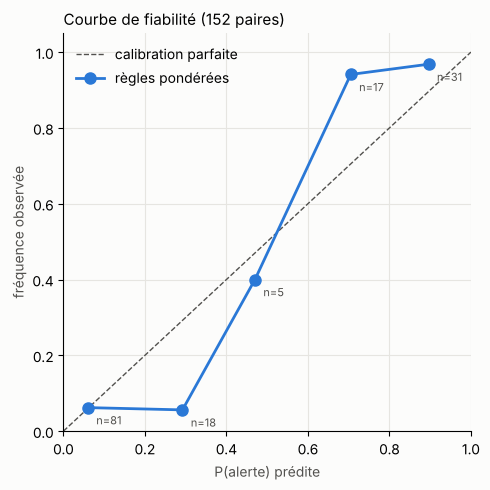

In [5]:
display(fiab)
fig, ax = plt.subplots(figsize=(5, 5), facecolor="#fcfcfb"); ax.set_facecolor("#fcfcfb")
ax.plot([0, 1], [0, 1], color="#52514e", linewidth=1, linestyle="--", label="calibration parfaite")
ax.plot(fiab["P moyenne"], fiab["fréquence observée"], color="#2a78d6", linewidth=2,
        marker="o", markersize=8, label="règles pondérées")
for _, r in fiab.iterrows():
    ax.annotate(f"n={r['paires']}", (r["P moyenne"], r["fréquence observée"]),
                textcoords="offset points", xytext=(6, -12), fontsize=8, color="#52514e")
ax.set_xlim(0, 1); ax.set_ylim(0, 1.05)
ax.set_xlabel("P(alerte) prédite", color="#52514e"); ax.set_ylabel("fréquence observée", color="#52514e")
for s in ("top", "right"):
    ax.spines[s].set_visible(False)
ax.grid(color="#e6e5e1", linewidth=0.8); ax.legend(frameon=False, loc="upper left")
ax.set_title("Courbe de fiabilité (152 paires)", loc="left", fontsize=11)
plt.tight_layout(); plt.show()

**Lecture.**

- Au seuil 0,5, ProbLog prend presque les mêmes décisions que le système déterministe (47 vraies alertes contre 48) : la pondération **ordonne** les alertes plus qu'elle ne les change. L'alerte perdue (warfarine + clarithromycine) ne repose que sur un signal G1 de poids 0,40.
- Le classement est bon (AUC 0,93) : les contre-indications et associations déconseillées sont en tête.
- La calibration est correcte aux extrêmes (tranches 0-0,2 et 0,8-1). La tranche 0,2-0,4 est **surestimée** (P moyenne 0,29, fréquence observée 0,06) : les poids des règles génériques sont trop hauts, et la tranche 0,6-0,8 est sous-estimée (règles expertes de niveau 1, poids 0,60). Ces poids pourraient être appris sur un jeu de validation séparé.
- Limite : l'indépendance supposée entre règles (« ou » bruité) est fausse quand deux règles décrivent le même mécanisme (R04 et G1 sur simvastatine + clarithromycine).